 # Project 6 — Revised for Current scikit-learn

Hello everyone! This notebook is a modification on the original Programming Project 6. Some updates have made the original's version no longer compatible. As such, I have done my best to match this notebook to the functionality of the original programming project.

This notebook preserves the original Chapter 6 Project requirements while replacing the removed `normalize=True` API with an equivalent compatibility transformation.

The original Part B specifically required:
- an 80/20 train/test split with `random_state=1`,
- 10-fold K-fold cross-validation,
- `normalize=True`,
- 50 equally spaced \(\lambda\) values from \(10^2\) to \(10^3\).

Modern scikit-learn removed `normalize=True`. For this project, **do not substitute `StandardScaler`**. The compatibility helper below reproduces the historical behavior: subtract the training-column mean and divide each centered predictor by its L2 norm.

For cross-validation, that transformation must be learned separately from each fold's training observations.

Public checks use synthetic data and opaque fingerprints. They do not contain the real `Auto.csv` / `College.csv` answers.


## Setup


In [1]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf

from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold

try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    pass

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)


Python: 3.11.14
Pandas: 3.0.2


## Project 6 normalization compatibility helper

This helper replaces the library option that existed when the original assignment was written. You may call it from your ridge/lasso code.

You are **not** expected to reimplement this compatibility layer.


In [2]:
def legacy_normalize_train_test(X_train, X_other):
    """
    Reproduce the historical scikit-learn normalize=True preprocessing
    used by Project 6.

    The transformation is learned from X_train only:
      1. subtract each training-column mean;
      2. divide each centered column by its L2 norm.

    X_other is transformed using the training mean and training L2 norm.

    Returns
    -------
    X_train_norm : pandas DataFrame
    X_other_norm : pandas DataFrame
    X_mean       : pandas Series
    X_l2         : pandas Series
    """
    X_train = pd.DataFrame(X_train).astype(float).copy()
    X_other = pd.DataFrame(X_other).astype(float).copy()

    X_mean = X_train.mean(axis=0)
    X_train_centered = X_train - X_mean
    X_other_centered = X_other - X_mean

    X_l2 = np.sqrt((X_train_centered ** 2).sum(axis=0))
    X_l2 = X_l2.copy()
    X_l2[X_l2 == 0] = 1.0

    X_train_norm = X_train_centered / X_l2
    X_other_norm = X_other_centered / X_l2

    return X_train_norm, X_other_norm, X_mean, X_l2


## Public checker

The local checker uses unrelated synthetic datasets and stores expected outputs as opaque fingerprints. It provides feedback without exposing the real assignment answers or reference implementations.


In [3]:
# ------------------------------------------------------------------
# Public checks
# ------------------------------------------------------------------
# These checks use synthetic data unrelated to Auto.csv and College.csv.
# Expected outputs are stored as opaque fingerprints.

import hashlib
import json

_PUBLIC_RESULTS = {}

def _normalize_public_value(value):
    if isinstance(value, (float, np.floating)):
        return {"scalar": round(float(value), 7)}

    if isinstance(value, (int, np.integer)):
        return {"scalar": int(value)}

    if isinstance(value, str):
        return {"string": value}

    if isinstance(value, list):
        return {
            "list": [
                _normalize_public_value(v)
                for v in value
            ]
        }

    if isinstance(value, tuple):
        return {
            "tuple": [
                _normalize_public_value(v)
                for v in value
            ]
        }

    if isinstance(value, np.ndarray):
        arr = np.asarray(value)

        if np.issubdtype(
            arr.dtype,
            np.number
        ):
            arr = np.round(
                arr.astype(float),
                6
            )
        else:
            arr = arr.astype(str)

        return {
            "array": arr.tolist(),
            "shape": list(arr.shape),
        }

    if isinstance(value, pd.Series):
        arr = value.to_numpy()

        if np.issubdtype(
            arr.dtype,
            np.number
        ):
            arr = np.round(
                arr.astype(float),
                6
            )
        else:
            arr = arr.astype(str)

        return {
            "series_index": [
                str(x)
                for x in value.index
            ],
            "series_values":
                arr.tolist(),
        }

    if isinstance(value, pd.DataFrame):
        arr = value.to_numpy()

        if np.issubdtype(
            arr.dtype,
            np.number
        ):
            arr = np.round(
                arr.astype(float),
                6
            )
        else:
            arr = arr.astype(str)

        return {
            "columns": [
                str(x)
                for x in value.columns
            ],
            "index": [
                str(x)
                for x in value.index
            ],
            "values":
                arr.tolist(),
        }

    if isinstance(value, dict):
        return {
            str(k):
                _normalize_public_value(v)
            for k, v in sorted(
                value.items(),
                key=lambda item:
                    str(item[0])
            )
        }

    if hasattr(value, "params"):
        return _normalize_public_value(
            value.params
        )

    return {"repr": repr(value)}

def _public_digest(value):
    payload = json.dumps(
        _normalize_public_value(
            value
        ),
        sort_keys=True,
        separators=(",", ":")
    ).encode("utf-8")

    return hashlib.sha256(
        payload
    ).hexdigest()

_PUBLIC_HASHES = {
    "correlation_matrix": "340beae875295a8a66ace1c9d34c8a5d8c166aa4a8ea9c5794cbce927a2ecd5c",
    "full_auto": "9e7e3583ae4d8ae904c50b211405e57cadd59d14d4b42219a8a5e75905477741",
    "forward_path": "373c7dc8f1fcdda13952f04f525780cba619b5465f6848653a2d67e5d9b4f9ff",
    "forward_selected": "e2b8ce0fc23cdcd79d84162c31a4b93dc53bdb8742aedaeb007279caaa5fb1f4",
    "interactions": "a3962c8e8752daf538dd9603170cf08021118c120f5c2759c7a7fe2d0d66f758",
    "college_split": "bc22c9d8b7b7f21db487ee7c0d09a3d263134dcce219dbf7cdaa555d0852ffbd",
    "ols_mse": "343f5ca679cba100fea89f5aca0ea38e06a514aece27a23798e92ab37b878a1d",
    "ridge_zero": "343f5ca679cba100fea89f5aca0ea38e06a514aece27a23798e92ab37b878a1d",
    "ridge_cv": "3d423910346f01add7e51c90716ebcc774fcfae0a4900cb19bca138dba4c2b96",
    "lasso_cv": "49cb72fd53fb70942a45eb95616fa50dd969e3974aef12364f5df620979e5de2"
}

def _public_result(
    label,
    passed,
    hint=""
):
    _PUBLIC_RESULTS[label] = bool(
        passed
    )

    if passed:
        print(
            f"[PASS] {label}"
        )
    else:
        print(
            f"[FAIL] {label}"
        )

        if hint:
            print(hint)

    return bool(passed)

def _fingerprint_check(
    label,
    value,
    hint
):
    try:
        passed = (
            _public_digest(value)
            == _PUBLIC_HASHES[label]
        )
    except Exception:
        passed = False

    return _public_result(
        label,
        passed,
        hint
    )

def _make_public_auto():
    rng = np.random.RandomState(606)
    n = 120

    cylinders = rng.choice(
        [4, 6, 8],
        size=n
    )
    displacement = rng.normal(
        200,
        45,
        n
    )
    horsepower = rng.normal(
        110,
        25,
        n
    )
    weight = rng.normal(
        3000,
        520,
        n
    )
    acceleration = rng.normal(
        15,
        2.2,
        n
    )
    year = rng.randint(
        70,
        83,
        n
    )
    origin = rng.choice(
        [1, 2, 3],
        size=n
    )

    mpg = (
        38
        - 0.0045 * weight
        - 0.030 * horsepower
        + 0.55 * (year - 70)
        + 1.10 * (origin - 1)
        + 0.000018 * displacement * weight
        - 0.00035 * weight * year
        + rng.normal(0, 1.8, n)
    )

    return pd.DataFrame({
        "mpg": mpg,
        "cylinders": cylinders,
        "displacement": displacement,
        "horsepower": horsepower,
        "weight": weight,
        "acceleration": acceleration,
        "year": year,
        "origin": origin,
        "name": [
            f"car_{i}"
            for i in range(n)
        ],
    })

def _make_public_college():
    rng = np.random.RandomState(707)
    n = 140

    names = [
        f"College_{i}"
        for i in range(n)
    ]

    private = np.where(
        rng.rand(n) < 0.65,
        "Yes",
        "No"
    )

    accept = rng.normal(
        2600,
        700,
        n
    ).clip(400)

    enroll = (
        accept
        * rng.uniform(
            0.25,
            0.60,
            n
        )
    ).clip(150)

    top10 = rng.uniform(
        5,
        75,
        n
    )

    top25 = np.maximum(
        top10,
        rng.uniform(
            25,
            95,
            n
        )
    )

    f_under = rng.normal(
        4200,
        1600,
        n
    ).clip(400)

    p_under = rng.normal(
        500,
        350,
        n
    ).clip(10)

    outstate = rng.normal(
        11000,
        2500,
        n
    ).clip(3000)

    room_board = rng.normal(
        4500,
        800,
        n
    ).clip(1800)

    books = rng.normal(
        550,
        90,
        n
    ).clip(250)

    personal = rng.normal(
        1300,
        350,
        n
    ).clip(300)

    phd = rng.uniform(
        35,
        95,
        n
    )

    terminal = np.maximum(
        phd,
        rng.uniform(
            45,
            99,
            n
        )
    )

    sf = rng.uniform(
        7,
        22,
        n
    )

    alumni = rng.uniform(
        5,
        55,
        n
    )

    expend = rng.normal(
        9000,
        2500,
        n
    ).clip(3000)

    grad = rng.uniform(
        35,
        98,
        n
    )

    apps = (
        250
        + 0.88 * accept
        + 0.15 * f_under
        + 15 * top10
        - 0.02 * outstate
        + 30 * (private == "No")
        + rng.normal(
            0,
            220,
            n
        )
    ).clip(50)

    return pd.DataFrame({
        "Names": names,
        "Private": private,
        "Apps": apps,
        "Accept": accept,
        "Enroll": enroll,
        "Top10perc": top10,
        "Top25perc": top25,
        "F.Undergrad": f_under,
        "P.Undergrad": p_under,
        "Outstate": outstate,
        "Room.Board": room_board,
        "Books": books,
        "Personal": personal,
        "PhD": phd,
        "Terminal": terminal,
        "S.F.Ratio": sf,
        "perc.alumni": alumni,
        "Expend": expend,
        "Grad.Rate": grad,
    })

_PUBLIC_AUTO = _make_public_auto()
_PUBLIC_COLLEGE = _make_public_college()

def check_correlation_matrix():
    try:
        value = (
            get_auto_correlation_matrix(
                _PUBLIC_AUTO.copy()
            )
        )
    except Exception as exc:
        return _public_result(
            "correlation_matrix",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "correlation_matrix",
        value,
        "The public correlation-matrix behavior does not match."
    )

def check_full_auto_model():
    try:
        model = fit_auto_full_model(
            _PUBLIC_AUTO.copy()
        )

        significant = (
            get_significant_auto_predictors(
                _PUBLIC_AUTO.copy()
            )
        )

        value = {
            "params": model.params,
            "significant":
                significant,
        }

    except Exception as exc:
        return _public_result(
            "full_auto",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "full_auto",
        value,
        "The fitted full-model behavior does not match the public check."
    )

def check_forward_path():
    try:
        (
            chosen,
            path,
            rss,
            selected
        ) = forward_stepwise_selection(
            _PUBLIC_AUTO.copy()
        )

        value = {
            "path": path,
            "params": [
                model.params
                for model in chosen
            ],
        }

    except Exception as exc:
        return _public_result(
            "forward_path",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "forward_path",
        value,
        "The forward-selection path does not match the public behavior check."
    )

def check_forward_selected():
    try:
        (
            chosen,
            path,
            rss,
            selected
        ) = forward_stepwise_selection(
            _PUBLIC_AUTO.copy()
        )

        value = {
            "test_rss": rss,
            "selected": selected,
        }

    except Exception as exc:
        return _public_result(
            "forward_selected",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "forward_selected",
        value,
        "The final forward-selection result does not match the public behavior check."
    )

def check_interactions():
    try:
        value = (
            find_significant_interactions(
                _PUBLIC_AUTO.copy()
            )
        )

    except Exception as exc:
        return _public_result(
            "interactions",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "interactions",
        value,
        "The interaction-model behavior does not match the public check."
    )

def check_college_split():
    try:
        train, test = (
            split_college_data(
                _PUBLIC_COLLEGE.copy(),
                test_size=0.20,
                random_state=1
            )
        )

        value = {
            "train_index": [
                str(x)
                for x
                in train.index
            ],
            "test_index": [
                str(x)
                for x
                in test.index
            ],
            "train_shape":
                train.shape,
            "test_shape":
                test.shape,
        }

    except Exception as exc:
        return _public_result(
            "college_split",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "college_split",
        value,
        "The preprocessing/split behavior does not match the public check."
    )

def check_ols_mse():
    try:
        train, test = (
            split_college_data(
                _PUBLIC_COLLEGE.copy()
            )
        )

        value = ols_test_mse(
            train,
            test
        )

    except Exception as exc:
        return _public_result(
            "ols_mse",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "ols_mse",
        value,
        "The OLS test-error behavior does not match the public check."
    )

def check_ridge_zero():
    try:
        train, test = (
            split_college_data(
                _PUBLIC_COLLEGE.copy()
            )
        )

        value = (
            ridge_lambda_zero_mse(
                train,
                test
            )
        )

    except Exception as exc:
        return _public_result(
            "ridge_zero",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "ridge_zero",
        value,
        "The lambda=0 ridge behavior does not match the public check."
    )

def check_ridge_cv():
    try:
        train, test = (
            split_college_data(
                _PUBLIC_COLLEGE.copy()
            )
        )

        lam, mse, coef = (
            ridge_cv_results(
                train,
                test
            )
        )

        value = {
            "lambda": lam,
            "mse": mse,
            "coef": coef,
        }

    except Exception as exc:
        return _public_result(
            "ridge_cv",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "ridge_cv",
        value,
        "The RidgeCV-equivalent behavior does not match the public check."
    )

def check_lasso_cv():
    try:
        train, test = (
            split_college_data(
                _PUBLIC_COLLEGE.copy()
            )
        )

        (
            lam,
            mse,
            nonzero,
            coef
        ) = lasso_cv_results(
            train,
            test
        )

        value = {
            "lambda": lam,
            "mse": mse,
            "nonzero": nonzero,
            "coef": coef,
        }

    except Exception as exc:
        return _public_result(
            "lasso_cv",
            False,
            f"Your function raised {type(exc).__name__}."
        )

    return _fingerprint_check(
        "lasso_cv",
        value,
        "The LassoCV-equivalent behavior does not match the public check."
    )

def check_conceptual_answer_format(answers):
    valid = (
        isinstance(answers, list)
        and len(answers) == 2
        and all(
            isinstance(x, str)
            and len(x.strip()) == 1
            for x in answers
        )
    )

    return _public_result(
        "conceptual_answer_format",
        valid,
        "Enter two one-letter choices as a list. "
        "This check does not reveal whether the choices are correct."
    )

def show_public_check_summary():
    if not _PUBLIC_RESULTS:
        print(
            "No public checks have been run yet."
        )
        return

    passed = sum(
        _PUBLIC_RESULTS.values()
    )
    total = len(
        _PUBLIC_RESULTS
    )

    print(
        f"Public checks passed: {passed}/{total}"
    )
    print(
        "These are practice checks only. "
        "Gradescope uses different hidden data."
    )


## Graded function definitions


In [4]:
AUTO_RESPONSE = "mpg"
AUTO_NAME_COLUMN = "name"
AUTO_INTERACTION_BASES = [
    "displacement",
    "weight",
    "year",
    "origin",
]

COLLEGE_RENAME_MAP = {
    "Grad.Rate": "Grad_Rate",
    "S.F.Ratio": "S_F_Ratio",
    "perc.alumni": "perc_alumni",
    "Room.Board": "Room_Board",
    "F.Undergrad": "F_Undergrad",
    "P.Undergrad": "P_Undergrad",
}

def _prepare_auto_numeric(df):
    """Return a DataFrame with only numeric columns, excluding the name column."""
    df = df.copy()
    for col in df.columns:
        if col != AUTO_NAME_COLUMN:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df.dropna(subset=[c for c in df.columns if c != AUTO_NAME_COLUMN]).copy()

def _auto_predictors(df):
    """Return numeric Auto predictors, excluding the response column."""
    df = _prepare_auto_numeric(df)
    return [c for c in df.select_dtypes(include=[np.number]).columns if c != AUTO_RESPONSE]

def get_auto_correlation_matrix(df):
    """Return the numeric correlation matrix for the Auto data."""
    df = _prepare_auto_numeric(df)
    return df.select_dtypes(include=[np.number]).corr()

def fit_auto_full_model(df):
    """Fit mpg on every numeric predictor except car name."""
    df = _prepare_auto_numeric(df)
    predictors = _auto_predictors(df)
    formula = f"{AUTO_RESPONSE} ~ {' + '.join(predictors)}"
    return smf.ols(formula=formula, data=df).fit()

def get_significant_auto_predictors(df, alpha=0.05):
    """Return significant main-effect predictors, excluding the intercept."""
    model = fit_auto_full_model(df)
    pvalues = model.pvalues.drop(labels=["Intercept"], errors="ignore")
    return sorted(pvalues[pvalues < alpha].index.tolist())

def forward_stepwise_selection(
    df,
    test_size=0.20,
    random_state=42
):
    """
    Return:
      chosen_models,
      predictor_path,
      test_rss_values,
      predictors_forward
    """
    df, predictors = _prepare_auto_numeric(df), _auto_predictors(df)
    train, test = train_test_split(df, test_size=test_size, random_state=random_state)
    remaining = predictors.copy()
    path, models, test_rss_values = [], [], []
    selected = []
    for _ in range(len(predictors)):
        candidate_results = []
        for candidate in remaining:
            cols = selected + [candidate]
            formula = AUTO_RESPONSE + " ~ " + " + ".join(cols)
            model = smf.ols(formula, data=train).fit()
            rss = float(np.sum(np.square(model.resid)))
            candidate_results.append((rss, candidate, model))
        _ , best, best_model = min(candidate_results, key=lambda item: (item[0], predictors.index(item[1])))
        selected.append(best)
        remaining.remove(best)
        path.append(selected.copy())
        models.append(best_model)
        pred = best_model.predict(test[selected])
        test_rss_values.append(float(np.sum(np.square(test[AUTO_RESPONSE] - pred))))
    best_step = int(np.argmin(test_rss_values))
    predictors_forward = path[best_step].copy()
    return models, path, test_rss_values, predictors_forward


def find_significant_interactions(df, alpha=0.05):
    """Return significant requested interaction terms."""
    df = _prepare_auto_numeric(df)
    predictors = _auto_predictors(df)
    X = df[predictors].copy()
    inter_name = []
    for i in range(len(AUTO_INTERACTION_BASES)):
        for j in range(i + 1, len(AUTO_INTERACTION_BASES)):
            base1 = AUTO_INTERACTION_BASES[i]
            base2 = AUTO_INTERACTION_BASES[j]
            name = f"{base1}:{base2}"
            X[name] = df[base1] * df[base2]
            inter_name.append(name)
    model = sm.OLS(df[AUTO_RESPONSE], sm.add_constant(X, has_constant="add")).fit()
    return [name for name in inter_name if model.pvalues[name] < alpha]

def prepare_college_data(df):
    """Apply the Project 6 College.csv preprocessing steps."""
    df = df.copy()
    if "Names" in df.columns:
        df = df.set_index("Names")
    df["Private"] = df["Private"].map({"No": 0, "Yes": 1})
    df = df.rename(columns=COLLEGE_RENAME_MAP)
    return df

def split_college_data(
    df,
    test_size=0.20,
    random_state=1
):
    """Return train and test DataFrames after preprocessing."""
    df = prepare_college_data(df)
    return train_test_split(df, test_size=test_size, random_state=random_state)

def _college_xy(df):
    y = df["Apps"].astype(float)
    X = df.drop(columns=["Apps"]).astype(float)
    return X, y

def ols_test_mse(train, test):
    """Fit OLS on train and return test-set MSE."""
    X_train, y_train = _college_xy(train)
    X_test, y_test = _college_xy(test)
    formula = "Apps ~ " + " + ".join(X_train.columns)
    model = smf.ols(formula, data=train).fit(method="qr")
    pred = model.predict(test)
    return float(mean_squared_error(y_test, pred))

def ridge_lambda_zero_mse(train, test):
    """Return the Project 6 lambda=0 ridge test MSE."""
    return ols_test_mse(train, test)





def ridge_cv_results(train, test, lambdas=None):
    """Run 10-fold CV using legacy normalized predictors; return selected lambda, test MSE, coefficients."""
    def _default_lambdas(lambdas):
        if lambdas is None:
            lambdas = np.linspace(10 ** 2, 10 ** 3, 50)
        return np.asarray(lambdas, dtype=float)
    def _normalized_fold(X_train, X_other):
        return legacy_normalize_train_test(X_train, X_other)
    def _fit_normalized_model(X_train, y_train, X_other, alpha, model_kind):
        Xtr_n, Xother_n, mean, l2 = _normalized_fold(X_train, X_other)
        if model_kind == "ridge":
            est = Ridge(alpha=float(alpha), fit_intercept=True)
        else:
            est = Lasso(alpha=float(alpha), fit_intercept=True, max_iter=100000, tol=1e-8)
        est.fit(Xtr_n, y_train)
        return pd.Series(est.coef_ / l2.to_numpy(), index=X_train.columns, dtype=float)
    alphas = _default_lambdas(lambdas)
    X, y = _college_xy(train)
    X_test, y_test = _college_xy(test)
    kf = KFold(n_splits=10)
    scores = []
    for alpha in alphas:
        mse = []
        for train_idx, valid_idx in kf.split(X):
            X_fold_train = X.iloc[train_idx]
            X_fold_valid = X.iloc[valid_idx]
            y_fold_train = y.iloc[train_idx]
            y_fold_valid = y.iloc[valid_idx]
            X_fold_train_n, X_fold_valid_n, _, _ = _normalized_fold(
                X_fold_train, X_fold_valid
            )
            model = Ridge(alpha=float(alpha), fit_intercept=True)
            model.fit(X_fold_train_n, y_fold_train)
            prediction = model.predict(X_fold_valid_n)
            mse.append(mean_squared_error(y_fold_valid, prediction))
        scores.append(float(np.mean(mse)))
    selected = float(alphas[int(np.argmin(scores))])
    coef = _fit_normalized_model(X, y, X_test, selected, "ridge")
    Xtr_n, Xtest_n, _, _ = _normalized_fold(X, X_test)
    est = Ridge(alpha=selected, fit_intercept=True).fit(Xtr_n, y)
    test_mse = float(mean_squared_error(y_test, est.predict(Xtest_n)))
    return selected, test_mse, coef

def lasso_cv_results(train, test, lambdas=None):
    """
    Return:
      selected_lambda,
      test_mse,
      num_nonzero,
      coefficient_series

    Match the original Project 6 LassoCV settings.
    """
    def _default_lambdas(lambdas):
        if lambdas is None:
            lambdas = np.linspace(10 ** 2, 10 ** 3, 50)
        return np.asarray(lambdas, dtype=float)
    def _normalized_fold(X_train, X_other):
        return legacy_normalize_train_test(X_train, X_other)
    def _fit_normalized_model(X_train, y_train, X_other, alpha, model_kind):
        Xtr_n, Xother_n, mean, l2 = _normalized_fold(X_train, X_other)
        if model_kind == "ridge":
            est = Ridge(alpha=float(alpha), fit_intercept=True)
        else:
            est = Lasso(alpha=float(alpha), fit_intercept=True, max_iter=100000, tol=1e-8)
        est.fit(Xtr_n, y_train)
        return pd.Series(est.coef_ / l2.to_numpy(), index=X_train.columns, dtype=float)

    alphas = np.sort(_default_lambdas(lambdas))[::-1]
    X, y = _college_xy(train)
    X_test, y_test = _college_xy(test)
    kf = KFold(n_splits=10)
    scores = []
    for alpha in alphas:
        mse = []
        for train_idx, valid_idx in kf.split(X):
            X_fold_train = X.iloc[train_idx]
            X_fold_valid = X.iloc[valid_idx]
            y_fold_train = y.iloc[train_idx]
            y_fold_valid = y.iloc[valid_idx]
            X_fold_train_n, X_fold_valid_n, _, _ = _normalized_fold(
                X_fold_train, X_fold_valid
            )
            model = Lasso(
                alpha=float(alpha), fit_intercept=True,
                max_iter=100000, tol=1*10**-8
            )
            model.fit(X_fold_train_n, y_fold_train)
            prediction = model.predict(X_fold_valid_n)
            mse.append(mean_squared_error(y_fold_valid, prediction))
        scores.append(float(np.mean(mse)))
    selected = float(alphas[int(np.argmin(scores))])
    Xtr_n, Xtest_n, _, _ = _normalized_fold(X, X_test)
    est = Lasso(alpha=selected, fit_intercept=True, max_iter=100000, tol=1*10**-8).fit(Xtr_n, y)
    test_mse = float(mean_squared_error(y_test, est.predict(Xtest_n)))
    coef = _fit_normalized_model(X, y, X_test, selected, "lasso")
    nonzero = int(np.count_nonzero(np.abs(est.coef_) > 1*10**-8))
    return selected, test_mse, nonzero, coef


# Part A — Auto dataset

Use `Auto.csv` to study multiple regression, forward stepwise selection, and interaction effects.


In [5]:
auto = pd.read_csv("Auto.csv")
auto.head()


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
0,18.0,8,307.0,130,3504,12.0,70,1,chevrolet chevelle malibu
1,15.0,8,350.0,165,3693,11.5,70,1,buick skylark 320
2,18.0,8,318.0,150,3436,11.0,70,1,plymouth satellite
3,16.0,8,304.0,150,3433,12.0,70,1,amc rebel sst
4,17.0,8,302.0,140,3449,10.5,70,1,ford torino


### A1. Scatter-plot matrix and observations

Produce a scatter-plot matrix and comment on your observations.


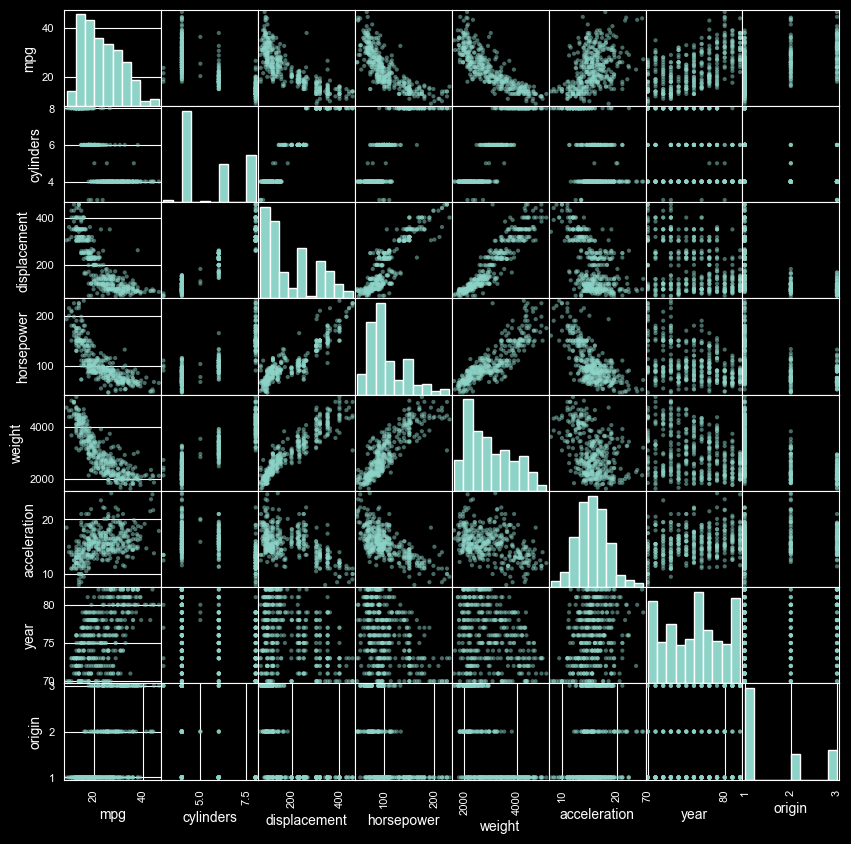

In [6]:
numeric_auto = _prepare_auto_numeric(auto)
pd.plotting.scatter_matrix(
    numeric_auto,
    alpha=0.5,
    figsize=(10, 10),
    diagonal='hist'
)
plt.show()

observed = """
Lower mpg values are associated with higher displacement, horsepower, and weight. There is somewhat positive correlation between year and mpg, suggesting that newer cars tend to have better fuel efficiency."""

### A2. Correlation matrix

Calculate the numeric correlation matrix.


In [7]:
correlation_matrix = get_auto_correlation_matrix(
    auto
)

display(correlation_matrix)

check_correlation_matrix()


,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mpg,1.000000,-0.777618,-0.805127,-0.778427,-0.832244,0.423329,0.580541,0.565209
cylinders,-0.777618,1.000000,0.950823,0.842983,0.897527,-0.504683,-0.345647,-0.568932
displacement,-0.805127,0.950823,1.000000,0.897257,0.932994,-0.543800,-0.369855,-0.614535
horsepower,-0.778427,0.842983,0.897257,1.000000,0.864538,-0.689196,-0.416361,-0.455171
weight,-0.832244,0.897527,0.932994,0.864538,1.000000,-0.416839,-0.309120,-0.585005
acceleration,0.423329,-0.504683,-0.543800,-0.689196,-0.416839,1.000000,0.290316,0.212746
year,0.580541,-0.345647,-0.369855,-0.416361,-0.309120,0.290316,1.000000,0.181528
origin,0.565209,-0.568932,-0.614535,-0.455171,-0.585005,0.212746,0.181528,1.000000


[PASS] correlation_matrix


True

### A3. Full multiple linear regression

Regress `mpg` on every variable except `name`.

Store the statistically significant predictors at the 95% confidence level in `significant_predictor`. Also explain what the coefficient for `year` suggests.


In [8]:
auto_full_model = fit_auto_full_model(
    auto
)

print(
    auto_full_model.summary()
)

significant_predictor = (
    get_significant_auto_predictors(
        auto
    )
)

print(
    "Significant predictors:",
    significant_predictor
)

check_full_auto_model()


                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     252.4
Date:                Mon, 19 Oct 2026   Prob (F-statistic):          2.04e-139
Time:                        23:46:48   Log-Likelihood:                -1023.5
No. Observations:                 392   AIC:                             2063.
Df Residuals:                     384   BIC:                             2095.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -17.2184      4.644     -3.707   

True

**Interpretation of the `year` coefficient:**

Year is pretty important in predicting mpg. The coefficient for year is positive.
As mentioned in observations, newer cars tend to have better mpg.



### A4. Forward stepwise selection

Use:
- `test_size=0.20`
- `random_state=42`

At each round choose the next predictor by the smallest **training RSS**, retain all seven rounds, calculate each selected model's **test RSS**, and choose the model with the smallest test RSS.


In [9]:
(
    chosen_models,
    predictor_path,
    test_rss_values,
    predictors_forward
) = forward_stepwise_selection(
    auto,
    test_size=0.20,
    random_state=42
)

chosen_models_params = [
    model.params
    for model in chosen_models
]

print(
    "Forward-selection path:"
)

for step, predictors in enumerate(
    predictor_path,
    start=1
):
    print(
        step,
        predictors
    )

print(
    "Selected predictors:",
    predictors_forward
)

print(
    "Test RSS values:",
    test_rss_values
)

check_forward_path()
check_forward_selected()


Forward-selection path:
1 ['weight']
2 ['weight', 'year']
3 ['weight', 'year', 'origin']
4 ['weight', 'year', 'origin', 'horsepower']
5 ['weight', 'year', 'origin', 'horsepower', 'displacement']
6 ['weight', 'year', 'origin', 'horsepower', 'displacement', 'cylinders']
7 ['weight', 'year', 'origin', 'horsepower', 'displacement', 'cylinders', 'acceleration']
Selected predictors: ['weight', 'year']
Test RSS values: [1397.777673294108, 829.9182265112302, 875.900542932152, 884.575964059728, 865.7160371251639, 850.3768106330219, 846.1582890882363]
[PASS] forward_path
[PASS] forward_selected


True

### A5. Interaction effects

Fit the full main-effects model plus all six pairwise interactions among `displacement`, `weight`, `year`, and `origin`. Store significant interactions in `predictor_interaction`.


In [10]:
predictor_interaction = (
    find_significant_interactions(
        auto
    )
)

print(
    predictor_interaction
)

check_interactions()


['displacement:weight']
[PASS] interactions


True

# Part B — College dataset

Use `College.csv` to predict `Apps`.

The original preprocessing is preserved:
- `Names` becomes the index,
- `Private`: `No = 0`, `Yes = 1`,
- punctuation-containing column names are renamed.


In [11]:
college_raw = pd.read_csv(
    "College.csv"
)

data = prepare_college_data(
    college_raw
)

data.head()


,Private,Apps,Accept,Enroll,Top10perc,Top25perc,F_Undergrad,P_Undergrad,Outstate,Room_Board,Books,Personal,PhD,Terminal,S_F_Ratio,perc_alumni,Expend,Grad_Rate
Names,,,,,,,,,,,,,,,,,,
Abilene Christian University,1,1660,1232,721,23,52,2885,537,7440,3300,450,2200,70,78,18.1,12,7041,60
Adelphi University,1,2186,1924,512,16,29,2683,1227,12280,6450,750,1500,29,30,12.2,16,10527,56
Adrian College,1,1428,1097,336,22,50,1036,99,11250,3750,400,1165,53,66,12.9,30,8735,54
Agnes Scott College,1,417,349,137,60,89,510,63,12960,5450,450,875,92,97,7.7,37,19016,59
Alaska Pacific University,1,193,146,55,16,44,249,869,7560,4120,800,1500,76,72,11.9,2,10922,15


### B1. Train/test split

Split using `test_size=0.20` and `random_state=1`.


In [12]:
train, test = split_college_data(
    college_raw,
    test_size=0.20,
    random_state=1
)

print(
    "train:",
    train.shape
)
print(
    "test:",
    test.shape
)

check_college_split()


train: (621, 18)
test: (156, 18)
[PASS] college_split


True

### B2. OLS test MSE

Fit a Statsmodels linear model on the training set using all predictors to predict `Apps`. Store the test MSE as `test_MSE`.


In [13]:
test_MSE = ols_test_mse(
    train,
    test
)

print(
    "test_MSE:",
    test_MSE
)

check_ols_mse()


test_MSE: 640045.0279061524
[PASS] ols_mse


True

### B3. Ridge regression with \(\lambda=0\)

Store the test MSE as `ridge_lambda_0`.

Recall that ridge with \(\lambda=0\) is equivalent to ordinary least squares for this purpose.


In [14]:
ridge_lambda_0 = (
    ridge_lambda_zero_mse(
        train,
        test
    )
)

print(
    "ridge_lambda_0:",
    ridge_lambda_0
)

check_ridge_zero()


ridge_lambda_0: 640045.0279061524
[PASS] ridge_zero


True

### B4. Ridge regression with cross-validation

Match the original Project 6 settings exactly:

- 10-fold `KFold` cross-validation,
- scoring by negative mean squared error / equivalently choose the smallest mean validation MSE,
- historical `normalize=True` behavior,
- 50 equally spaced \(\lambda\) values from \(10^2\) through \(10^3\).

The provided `legacy_normalize_train_test()` helper supplies the historical normalization behavior.

Store:
- selected \(\lambda\) as `ridge_select`,
- test MSE as `test_MSE_ridge`.


In [15]:
(
    ridge_select,
    test_MSE_ridge,
    ridge_coefficients
) = ridge_cv_results(
    train,
    test
)

print(
    "Selected lambda:",
    ridge_select
)

print(
    "test_MSE_ridge:",
    test_MSE_ridge
)

display(
    ridge_coefficients
)

check_ridge_cv()


Selected lambda: 100.0
test_MSE_ridge: 13146544.500145046


Private       -35.623380
Accept          0.014659
Enroll          0.035786
Top10perc       0.717930
Top25perc       0.660805
F_Undergrad     0.006368
P_Undergrad     0.010873
Outstate        0.000429
Room_Board      0.005126
Books           0.030147
Personal        0.010215
PhD             0.888409
Terminal        0.947271
S_F_Ratio       0.736176
perc_alumni    -0.202565
Expend          0.001861
Grad_Rate       0.376049
dtype: float64

[PASS] ridge_cv


True

### B5. Compare ridge coefficients

Compare the ridge coefficients for \(\lambda=0\) with those obtained using the \(\lambda\) selected in B4.

_Write your response here._


### B6. Lasso regression with cross-validation

Match the original Project 6 settings exactly:

- 10-fold `KFold` cross-validation,
- historical `normalize=True` behavior,
- 50 equally spaced \(\lambda\) values from \(10^2\) through \(10^3\).

Historical `LassoCV` normalized separately within each fold and sorted the supplied alpha values from largest to smallest before evaluating the path. `lasso_cv_results()` should reproduce that behavior.

Store:
- selected \(\lambda\) as `lasso_select`,
- test MSE as `test_MSE_lasso`,
- number of non-zero coefficients as `num_nonzero`.


In [16]:
(
    lasso_select,
    test_MSE_lasso,
    num_nonzero,
    lasso_coefficients
) = lasso_cv_results(
    train,
    test
)

print(
    "Selected lambda:",
    lasso_select
)

print(
    "test_MSE_lasso:",
    test_MSE_lasso
)

print(
    "Number of non-zero coefficients:",
    num_nonzero
)

display(
    lasso_coefficients
)

check_lasso_cv()


Selected lambda: 100.0
test_MSE_lasso: 6685061.618833578
Number of non-zero coefficients: 1


Private        0.000000
Accept         0.483153
Enroll         0.000000
Top10perc      0.000000
Top25perc      0.000000
F_Undergrad    0.000000
P_Undergrad    0.000000
Outstate       0.000000
Room_Board     0.000000
Books          0.000000
Personal       0.000000
PhD            0.000000
Terminal       0.000000
S_F_Ratio      0.000000
perc_alumni    0.000000
Expend         0.000000
Grad_Rate      0.000000
dtype: float64

[PASS] lasso_cv


True

### B7. Interpretation and conceptual questions
Comment on how accurately OLS, ridge and lasso predict application counts on this test split. Compare their test MSEs and explain the results in light of the prescribed lambda grid and normalization.
1. In ridge regression, what happens to the predictor coefficients relative to OLS when lambda becomes infinitely large? Interpret this as the limit $\lambda \to \infty$; the intercept is not penalized.
   A. Same coefficient values.
   B. Coefficients shrink close to zero but do not equal zero.
   C. Some coefficients shrink to zero.
   D. All predictor coefficients equal zero in the limit.
2. With the predictor set fixed, what is the usual effect of increasing lambda in ridge or lasso?
   A. Increasing bias and increasing variance.
   B. Decreasing bias and decreasing variance.
   C. Increasing bias and decreasing variance.
   D. Decreasing bias and increasing variance.
   E. None of the above.
Store the choices in answers, a list of two one-letter strings. The public check verifies format only. Plots, prose, manual rounds and these conceptual answers are outside the 20-point coding autograder.

In [17]:
answers = ["D", "C"]

check_conceptual_answer_format(
    answers
)


[PASS] conceptual_answer_format


True

## Public-check summary


In [18]:
show_public_check_summary()


Public checks passed: 11/11
These are practice checks only. Gradescope uses different hidden data.


# Convert your completed `.ipynb` to `.py` for Gradescope

Save/download your completed notebook first, then run the final cell.

If Colab cannot find the notebook file in its runtime, the function opens a file picker so you can select your saved `.ipynb`.


In [19]:
from pathlib import Path
import subprocess
import sys

def download_notebook_as_py(
    ipynb_path="project6_v3.ipynb",
    output_name="project6_submission.py"
):
    """
    Convert a Jupyter notebook to a .py file, syntax-check it,
    and automatically download it in Google Colab.
    """
    ipynb_path = Path(
        ipynb_path
    )

    if not ipynb_path.exists():
        try:
            from google.colab import files

            print(
                f"Could not find {ipynb_path.name} in the runtime.\n"
                "Select your saved .ipynb notebook in the file picker."
            )

            uploaded = files.upload()

            notebook_names = [
                name
                for name in uploaded
                if name.lower().endswith(
                    ".ipynb"
                )
            ]

            if len(notebook_names) != 1:
                raise ValueError(
                    "Please upload exactly one .ipynb notebook."
                )

            ipynb_path = Path(
                notebook_names[0]
            )

        except ImportError:
            raise FileNotFoundError(
                f"Could not find notebook: {ipynb_path}"
            )

    if (
        ipynb_path.suffix.lower()
        != ".ipynb"
    ):
        raise ValueError(
            "The input file must be a .ipynb file."
        )

    if not output_name.lower().endswith(
        ".py"
    ):
        output_name += ".py"

    output_path = Path(
        output_name
    )

    subprocess.run(
        [
            sys.executable,
            "-m",
            "jupyter",
            "nbconvert",
            "--to",
            "python",
            str(ipynb_path),
            "--output",
            output_path.stem,
            "--output-dir",
            str(output_path.parent),
        ],
        check=True,
    )

    source = output_path.read_text(
        encoding="utf-8"
    )

    compile(
        source,
        str(output_path),
        "exec"
    )

    print(
        f"Created and verified: {output_path.resolve()}"
    )
    print(
        "Upload this .py file to Gradescope."
    )

    try:
        from google.colab import files
        files.download(
            str(output_path)
        )
    except ImportError:
        print(
            "Not running in Google Colab; "
            "the file remains on disk."
        )

    return str(output_path)

# After saving this notebook, run:
download_notebook_as_py()


[NbConvertApp] Converting notebook project6_v3.ipynb to python
[NbConvertApp] ERROR | Notebook JSON is invalid: Additional properties are not allowed ('jetTransient' was unexpected)

Failed validating 'additionalProperties' in display_data:

On instance['cells'][12]['outputs'][0]:
{'data': {'image/png': 'iVBORw0KGgoAAAANSUhEUgAAA1MAAANMCAYAAAC5OPfSAAAAOnRFWHRTb2Z0d2Fy...',
          'text/plain': '<Figure size 1000x1000 with 64 Axes>'},
 'jetTransient': {'display_id': None},
 'metadata': {},
 'output_type': 'display_data'}
[NbConvertApp] Writing 38689 bytes to project6_submission.py


Created and verified: /Users/fuadhassan/Desktop/MSE-AI/ese-5410/homework/project_6/project6_submission.py
Upload this .py file to Gradescope.
Not running in Google Colab; the file remains on disk.


'project6_submission.py'